<a href="https://colab.research.google.com/github/sauravv-kunwar/Deep-Learning/blob/main/Early_Stopping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Early Stopping in Neural Networks

## Definition

Early Stopping is a regularization technique used in Neural Networks to prevent overfitting by stopping the training process when the model's performance on validation data stops improving.

During training, a neural network gradually learns patterns from the training dataset. However, after a certain number of epochs, the model may start memorizing the training data instead of learning general patterns. This leads to overfitting.

Early Stopping monitors the validation loss after each epoch and stops training when the validation loss stops decreasing or starts increasing.

## How Early Stopping Works

1. Divide the dataset into training and validation sets.
2. Train the neural network using the training dataset.
3. Calculate the validation loss after each epoch.
4. Monitor the validation loss to check whether the model is improving.
5. If the validation loss does not improve for a specified number of consecutive epochs, stop training.
6. Restore the model weights from the epoch that achieved the best validation performance.

## Important Parameters

- **Monitor:** The metric monitored during training, usually `val_loss`.
- **Patience:** Number of consecutive epochs allowed without improvement before stopping training.
- **Min_delta:** Minimum change required to consider an improvement.
- **Restore_best_weights:** Restores the model weights from the epoch with the best monitored performance.

## Advantages of Early Stopping

- Prevents overfitting.
- Reduces unnecessary training time.
- Improves model generalization on unseen data.
- Helps select the best-performing model during training.
- Saves computational resources.

## Example

Suppose a neural network is trained for 100 epochs.

- Initially, both training loss and validation loss decrease.
- After 30 epochs, validation loss starts increasing while training loss continues decreasing.
- If the patience is set to 5, training stops after 5 consecutive epochs without validation loss improvement.
- The model can restore the weights from the epoch where validation loss was lowest.

## Conclusion

Early Stopping is an effective regularization technique that monitors validation performance and automatically stops training when the model stops improving. It helps prevent overfitting, saves training time, and improves the generalization ability of a neural network.


# Code Demo


In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
from pylab import rcParams
import matplotlib.pyplot as plt
import warnings
from mlxtend.plotting import plot_decision_regions
from matplotlib.colors import ListedColormap
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
import seaborn as sns

In [2]:
X, y = make_circles(n_samples=100, noise=0.1, random_state=1)

<Axes: >

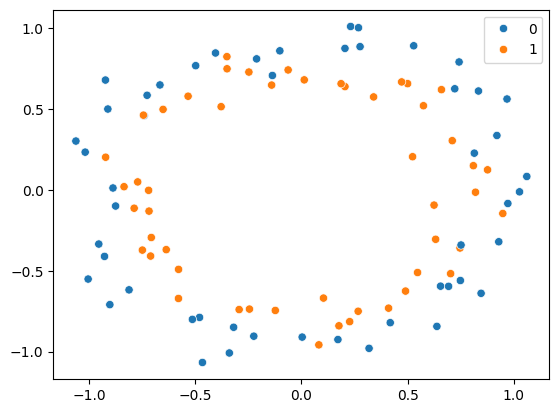

In [5]:
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=2)

In [7]:
model = Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [21]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, verbose=0)

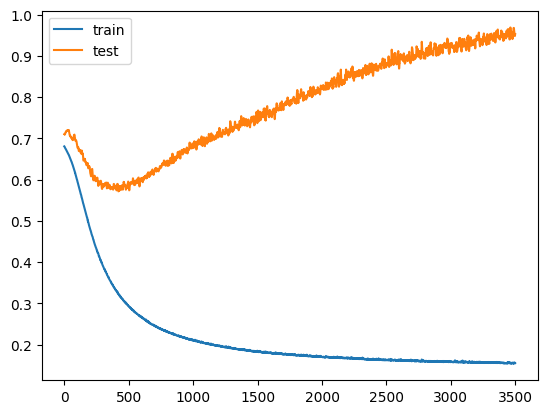

In [22]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step


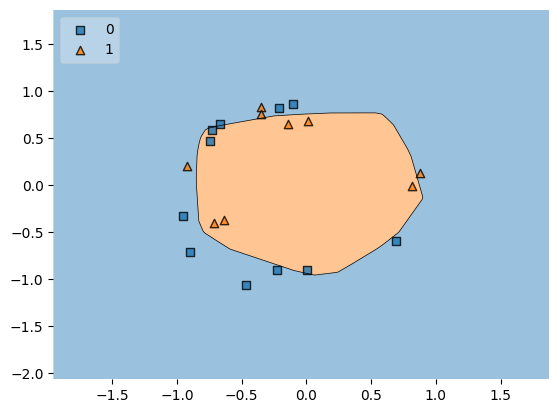

In [13]:
plot_decision_regions(X_test, y_test.ravel(), clf = model, legend=2)
plt.show()

# Early Stoppping

In [14]:
model = Sequential()

model.add(Dense(256, input_dim = 2, activation = 'relu'))
model.add(Dense(1,activation = 'sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
model.compile(loss = 'binary_crossentropy',optimizer = 'adam',metrics = ['accuracy'])

In [17]:
callback = EarlyStopping(
    monitor = 'val_loss',
    min_delta = 0.00001,
    patience = 5,
    verbose = 1,
    mode = 'auto',
    restore_best_weights = False
)

In [23]:
hisotry = model.fit(X_train,y_train,validation_data = (X_test,y_test),epochs = 3500,callbacks = callback)

Epoch 1/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9375 - loss: 0.1561 - val_accuracy: 0.6500 - val_loss: 0.9531
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9500 - loss: 0.1553 - val_accuracy: 0.6500 - val_loss: 0.9610
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9375 - loss: 0.1551 - val_accuracy: 0.6500 - val_loss: 0.9641
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9500 - loss: 0.1561 - val_accuracy: 0.6500 - val_loss: 0.9648
Epoch 5/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9500 - loss: 0.1549 - val_accuracy: 0.6500 - val_loss: 0.9682
Epoch 5: early stopping


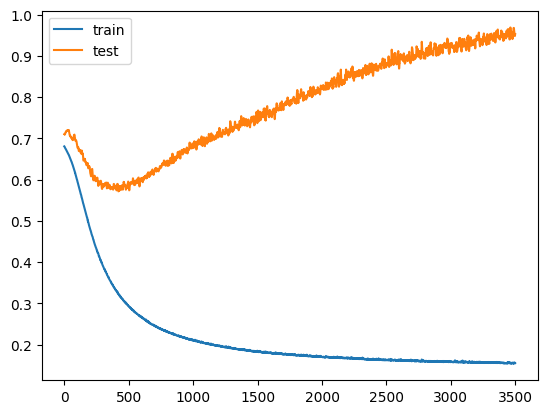

In [24]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 13s 1ms/step


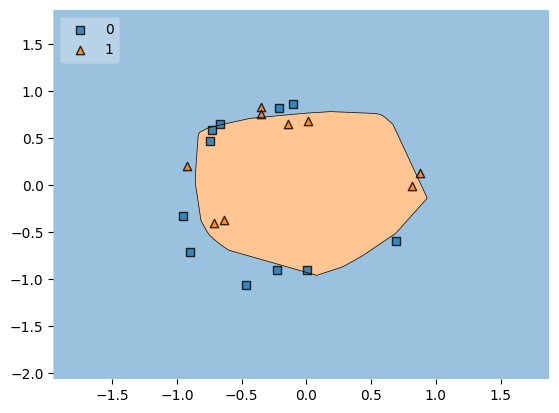

In [25]:
plot_decision_regions(X_test, y_test.ravel(), clf = model, legend=2)
plt.show()